# 04 · Noise calibration against PETRI-seq (A5)
**Data:** Blattman et al. 2020, PETRI-seq, GEO GSE141018 (`GSM4489500` E. coli library 2.01, growing vs stationary).
**Goal:** layer per-cell noise onto the A3 circuit so that simulated cells look like real single cells, then check that the
simulator reproduces a growing/stationary split on the circuit's own genes.

Steps: (1) load the real cells (`load_scrnaseq.py`) · (2) fit noise by method of moments + a small ABC check (`fit_noise_params.py`)
· (3) simulate the same number of cells with the A4 engine and compare (`a5_validate.py`, `a5_figures.py`).

In [1]:
import sys, json; sys.path.insert(0, '../src')
from pathlib import Path
from IPython.display import Image, display
import pandas as pd
ROOT = Path('..'); A5 = ROOT/'outputs'/'a5'
S = json.loads((ROOT/'data/scrnaseq/GSE141018/petri_2_01_summary.json').read_text())
print('cells used:', S['cells']['n_exp'], 'growing /', S['cells']['n_stat'], 'stationary')
print('PC1 split on all operons, AUC =', S['phase_split']['all_operons_pc1']['auc'], '(paper: 99.97% correct)')

cells used: 3430 growing / 4499 stationary
PC1 split on all operons, AUC = 1.0 (paper: 99.97% correct)


## 1 · Real cells
The full-genome split reproduces the paper. Restricted to the 17 circuit operons the split is weaker (AUC 0.81).
The lac operon is almost silent in these cells (no inducer): ~1% of growing cells have a lacZYA UMI.

In [2]:
pd.DataFrame({op: {'growing mean UMI': v['exp'][0], 'stationary mean UMI': v['stat'][0]} for op, v in S['operons'].items() if isinstance(v, dict) and 'exp' in v}).T.round(3)

,growing mean UMI,stationary mean UMI
lacZYA,0.013,0.006
lacI,0.018,0.002
crp,0.067,0.047
cyaA,0.074,0.043
gat,0.169,0.087
hflC,0.644,0.103
tdcB,0.019,0.005
uhpT,0.002,0.001
cas3,0.004,0.003
rbs,0.152,0.010


## 2 · Fitted noise

In [3]:
F = json.loads((A5/'noise_fit.json').read_text())
pd.Series(F['chosen']).to_frame('value')

,value
output_extrinsic_cv2,0.102106
output_extrinsic_cv2_se,0.042235
output_burst_b,0.000000
output_burst_b_upper95,0.541713
crp_extrinsic_sigma,0.000000
crp_extrinsic_sigma_upper95,1.831595
lac_protein_burst,4.200000
tpm_to_molecules,0.004440
capture_per_molecule_q0,0.050000


In [4]:
print('method of moments: eta2 =', round(F['chosen']['output_extrinsic_cv2'],3))
print('ABC accepted region:', 'eta2', F['abc']['eta2_accepted_range'], ' b', F['abc']['b_accepted_range'], ' best', F['abc']['best'])

method of moments: eta2 = 0.102
ABC accepted region: eta2 [0.0, 0.125]  b [0.0, 0.5]  best {'eta2': 0.0, 'b': 0.5, 'distance': 12.841834108378842}


**Reading it:** extra (extrinsic) cell-to-cell variation of about 10% CV² per gene; no detectable transcriptional bursting
above Poisson at this capture depth; shared CRP noise is not pinned down (gene–gene correlations ≈ 0 after capture).
The ABC check accepts η² between 0 and 0.125, which contains the method-of-moments value 0.10 ± 0.04; ABC trades η² against burst size b
because at ~1 UMI per cell they produce almost the same histograms, so we keep the moment estimate (it uses the mean–variance trend
across all genes) and quote the ABC range as the uncertainty.

## 3 · Simulated vs real

In [5]:
V = json.loads((A5/'validation.json').read_text())
for k in ('calibrated','uncalibrated'):
    a = V[k]['agreement']['exp']
    print(f"{k:13s} growing-cell histograms chi2/dof = {a['hist_chi2']/a['hist_dof']:.2f}   Fano RMSE = {a['fano_rmse_expressed']:.3f}   circuit-gene AUC = {V[k]['pca17']['auc']:.2f}")
print('real circuit-gene AUC =', V['real']['pca17_auc'])

calibrated    growing-cell histograms chi2/dof = 1.53   Fano RMSE = 0.067   circuit-gene AUC = 0.65
uncalibrated  growing-cell histograms chi2/dof = 1.76   Fano RMSE = 0.095   circuit-gene AUC = 0.71
real circuit-gene AUC = 0.806


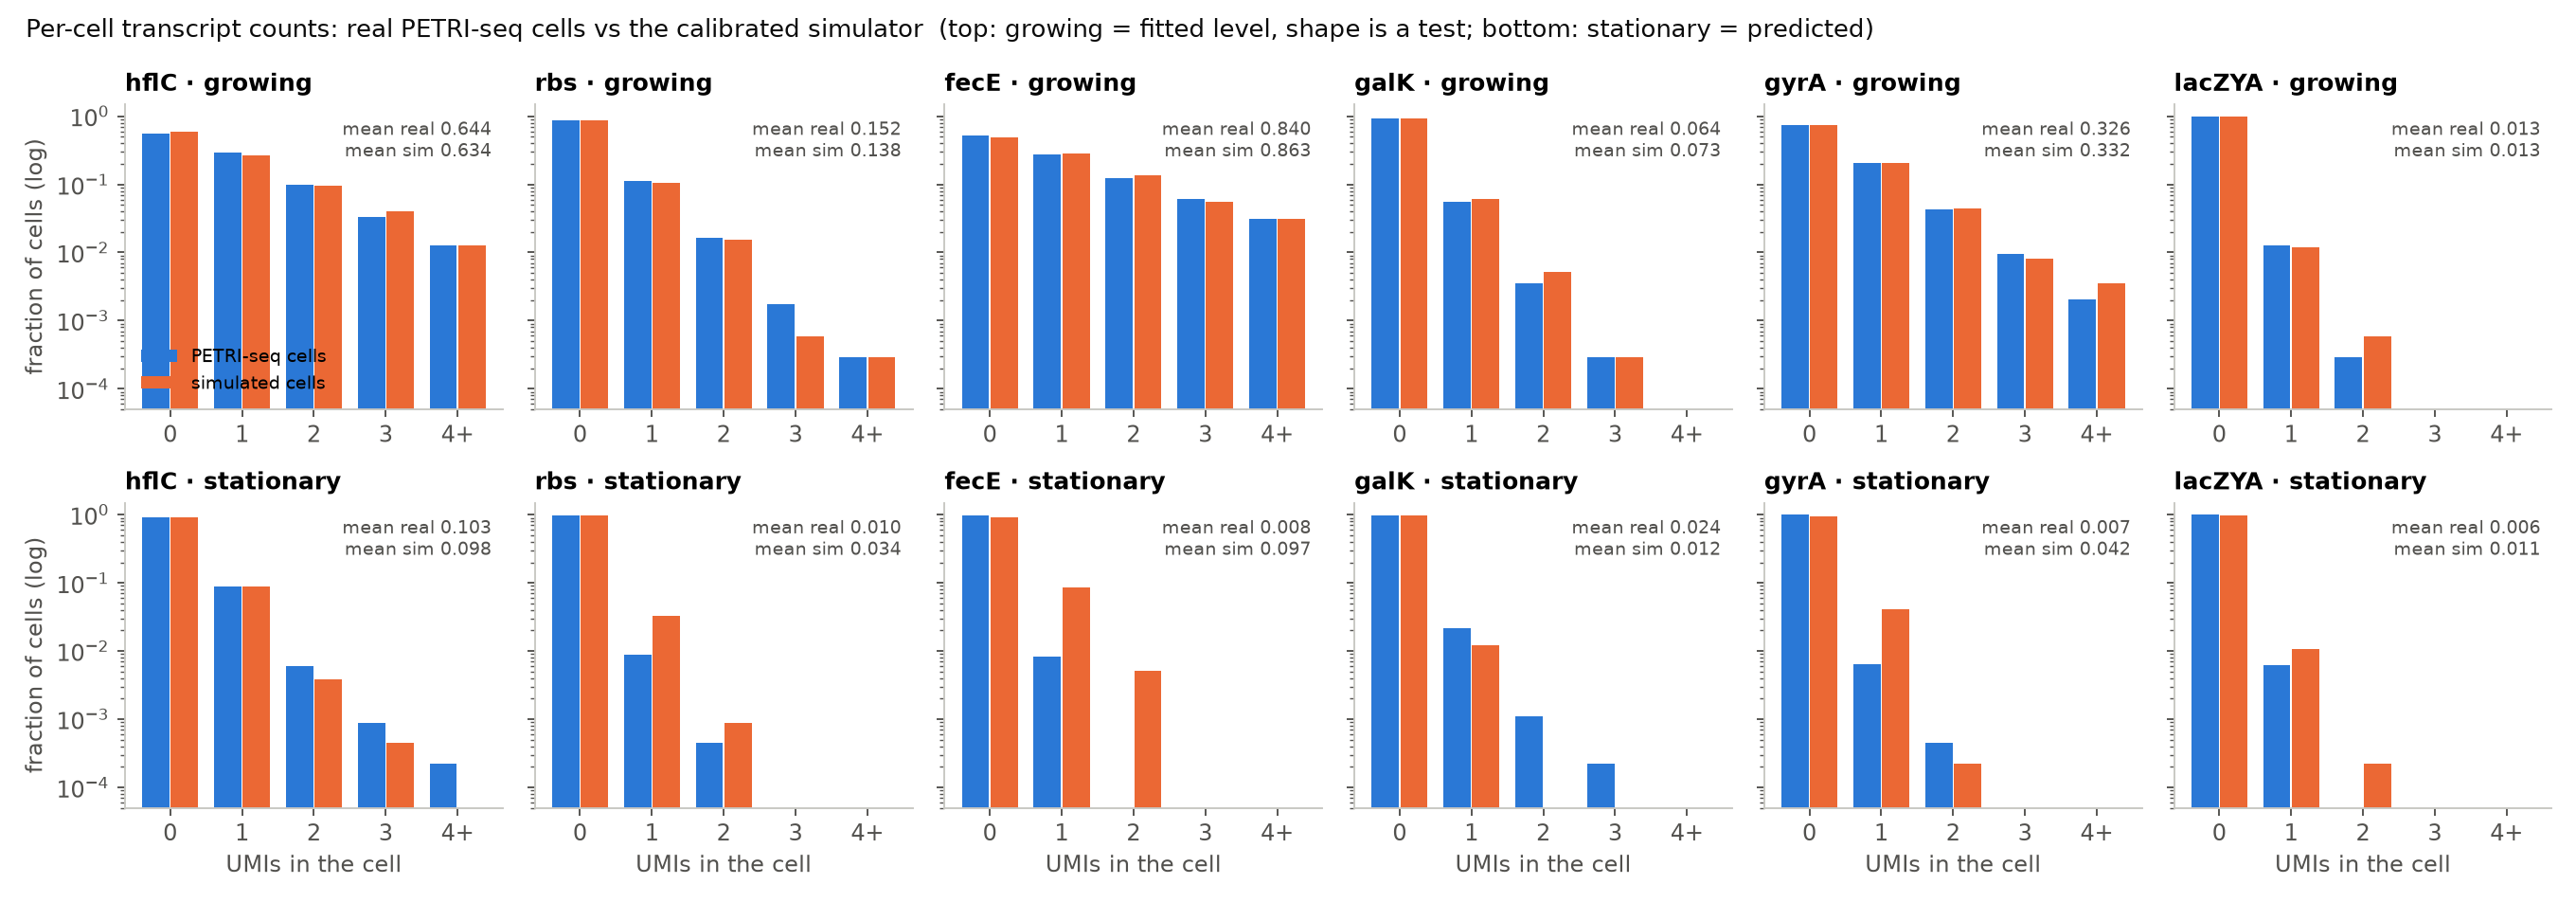

In [6]:
display(Image(A5/'fig_distributions.png'))

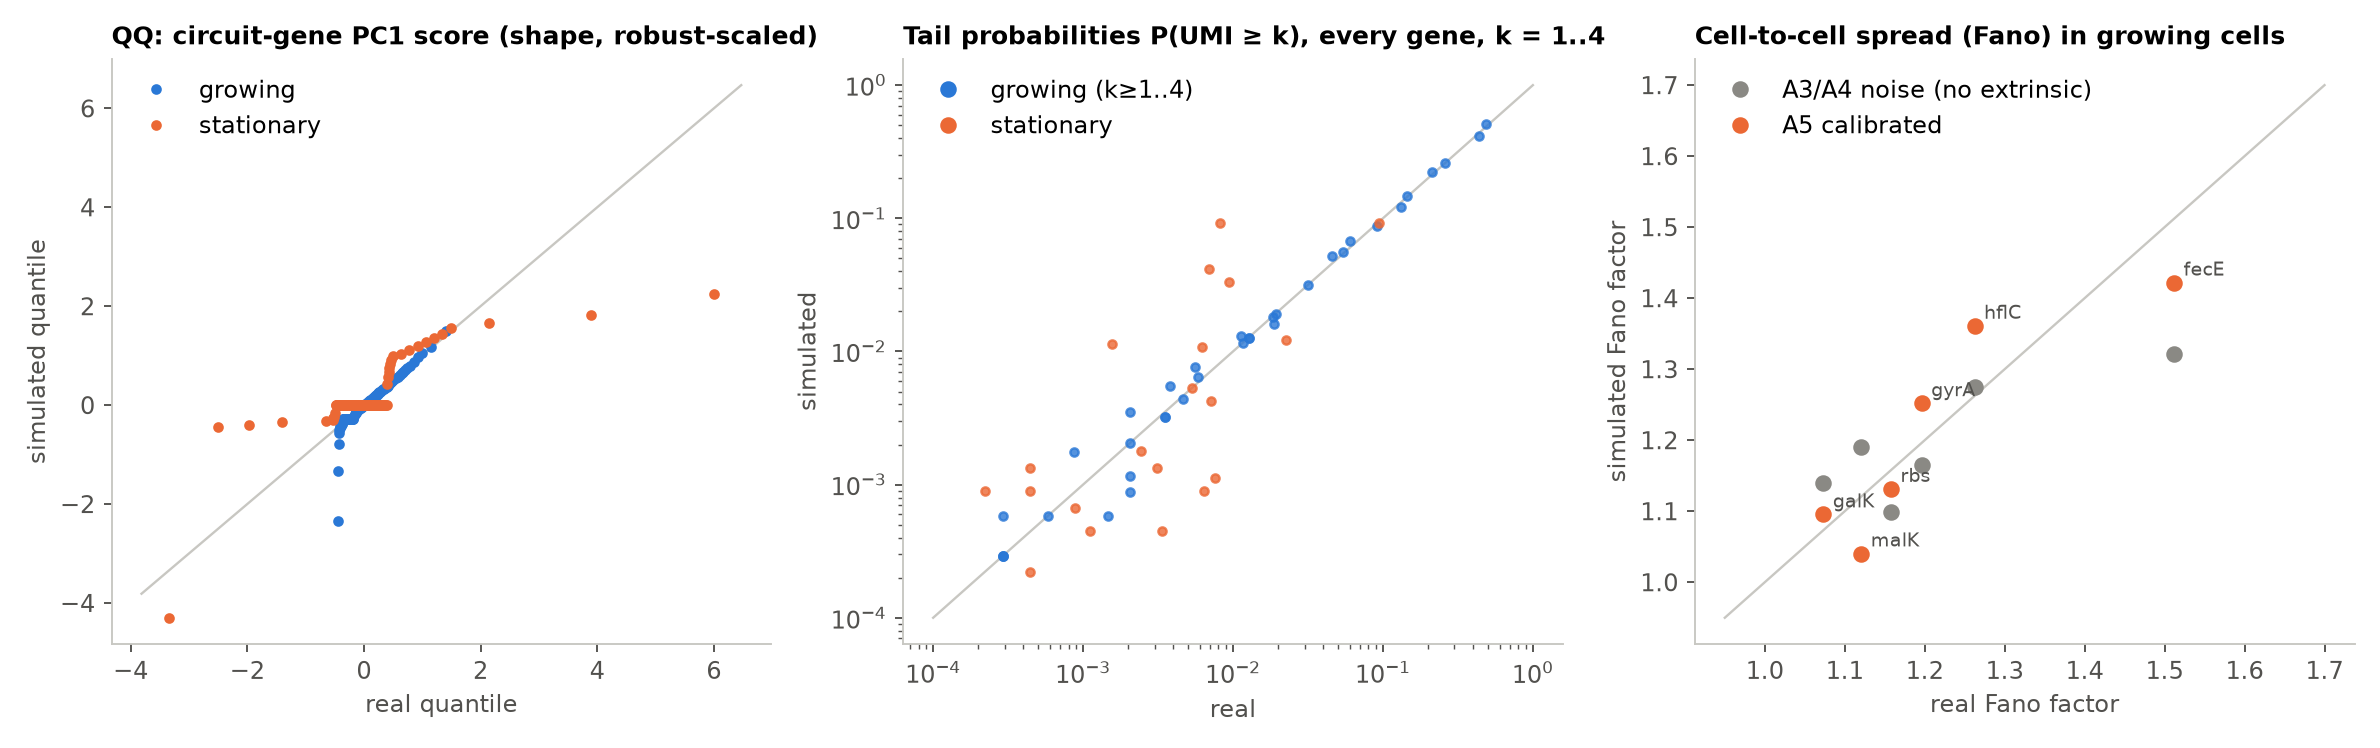

In [7]:
display(Image(A5/'fig_qq.png'))

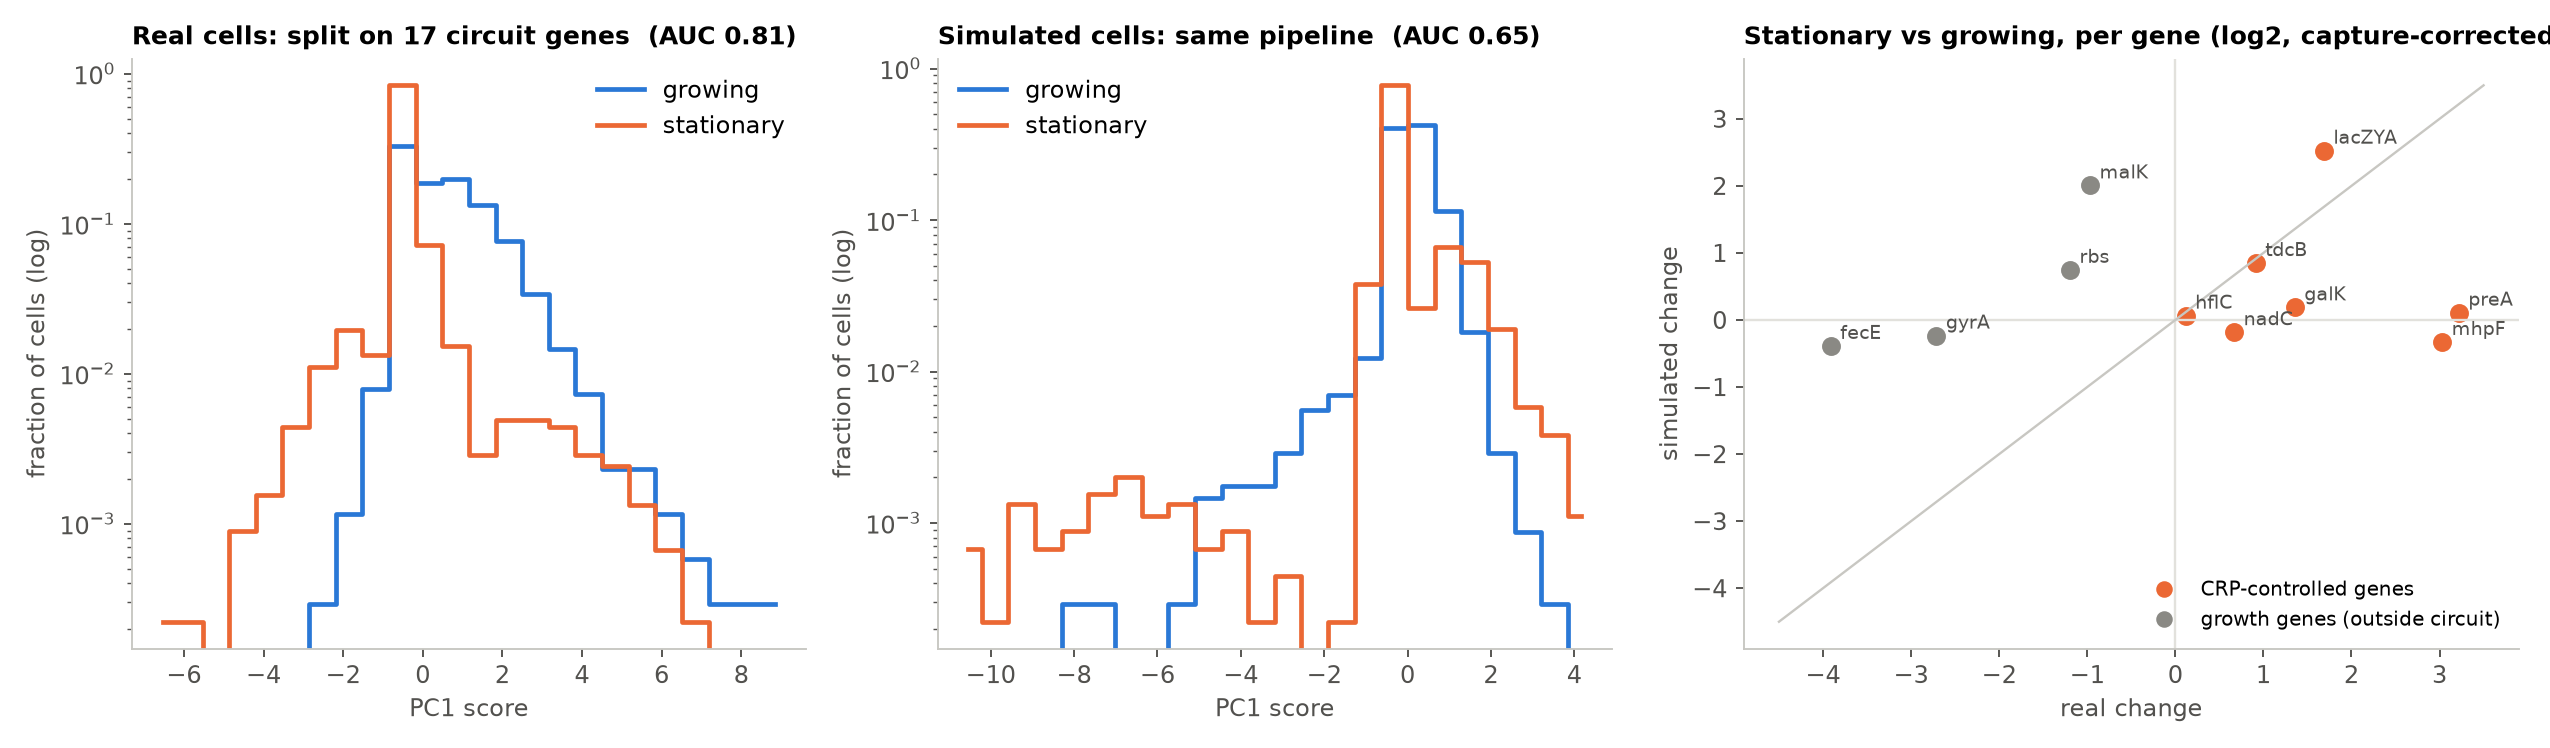

In [8]:
display(Image(A5/'fig_phase_split.png'))

## 4 · Consequence for the lac switch (A4 leak)

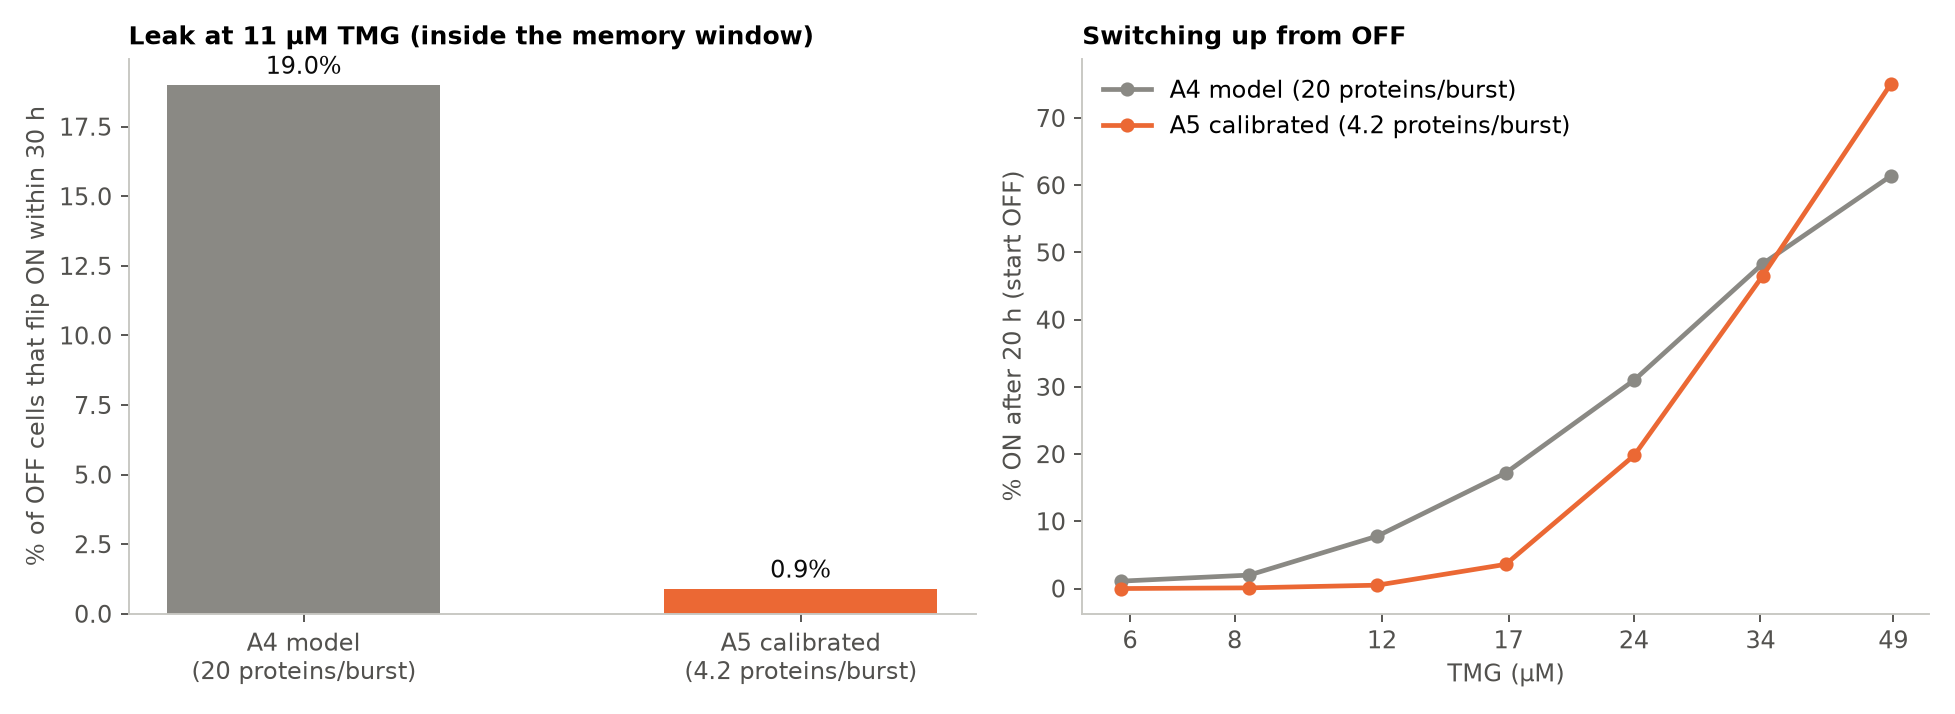

In [9]:
display(Image(A5/'fig_lac_memory.png'))

## 5 · Using the calibrated model downstream (A6, Student B Module 4)

In [10]:
from ssa_simulator import StochasticCircuit
from perturbation import InducerLevelChange
sc = StochasticCircuit(ROOT/'outputs/a5/calibrated_circuit_model.yaml', mode='fast')
tr = sc.run(InducerLevelChange(30.0, n_cells=300, seed=1))
print(tr.summary_stats())

{'time_min': 1200.0, 'n_cells': 300, 'species': {'P_free_count': {'mean': 0.38333333333333336, 'variance': 0.23717948717948725, 'fano': 0.6187290969899667, 'second_half_mean': 0.2799173553719008, 'second_half_variance': 0.2015691824035405, 'second_half_fano': 0.7201024821620431}, 'P_rep_count': {'mean': 0.6166666666666667, 'variance': 0.23717948717948714, 'fano': 0.3846153846153845, 'second_half_mean': 0.7200826446280991, 'second_half_variance': 0.20156918240354044, 'second_half_fano': 0.27992506680624807}, 'M_count': {'mean': 2.23, 'variance': 9.52886287625418, 'fano': 4.273032679934611, 'second_half_mean': 1.6741322314049587, 'second_half_variance': 8.435833223099515, 'second_half_fano': 5.038928864071883}, 'Y_count': {'mean': 518.8833333333333, 'variance': 424734.72547380155, 'fano': 818.5553441180771, 'second_half_mean': 343.24790633608814, 'second_half_variance': 308472.08959174855, 'second_half_fano': 898.6860047726288}, 'X_count': {'mean': 14728.576666666666, 'variance': 3422163